# LiarTree vs ClusTree Evaluation

Reads best-trial results from `param_sweep_results/summary.csv` and plots CMM, F1, purity, and cluster count against noise level, comparing LiarTree and ClusTree on each base dataset.

In [1]:
import re

import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("param_sweep_results/summary.csv")
df.head()

,algorithm,dataset,score,cmm,f1,purity,n_clusters,param_lam,param_noise_threshold,param_eps,param_min_samples
0,liartree,complex9,0.271160,0.545677,0.196643,0.5430,6,0.000036,0.459531,0.073220,1
1,liartree,complex9_noise10,0.371152,0.824819,0.157485,0.5315,6,0.000012,0.964495,0.075864,1
2,liartree,complex9_noise20,0.499986,0.746422,0.313551,0.5460,9,0.000220,0.992984,0.009119,1
3,liartree,complex9_noise30,0.442761,0.872378,0.133143,0.4005,8,0.001765,0.279316,0.007340,1
4,liartree,complex9_noise40,0.264923,0.952806,0.057041,0.3990,2,0.012079,0.155755,0.176050,1


In [2]:
# Split each dataset name into its base dataset and noise level, e.g.
# "complex9_noise30" -> base="complex9", noise=30; "complex9" -> base="complex9", noise=0.
def split_dataset(name):
    match = re.match(r"^(.*)_noise(\d+)$", name)
    if match:
        return match.group(1), int(match.group(2))
    return name, 0

df[["base_dataset", "noise"]] = df["dataset"].apply(lambda d: pd.Series(split_dataset(d)))
df.sort_values(["base_dataset", "algorithm", "noise"])

,algorithm,dataset,score,cmm,f1,purity,n_clusters,param_lam,param_noise_threshold,param_eps,param_min_samples,base_dataset,noise
12,clustree,complex9,0.880749,0.997031,0.897800,0.9960,11,0.028251,NaN,0.034087,15,complex9,0
13,clustree,complex9_noise10,0.867092,0.950513,0.783671,0.8930,10,0.000962,NaN,0.036030,14,complex9,10
14,clustree,complex9_noise20,0.459445,0.944179,0.034711,0.2370,9,0.000019,NaN,0.049929,1,complex9,20
15,clustree,complex9_noise30,0.576977,0.871730,0.402223,0.4425,12,0.000618,NaN,0.024843,5,complex9,30
16,clustree,complex9_noise40,0.461674,0.827370,0.335979,0.3955,6,0.063521,NaN,0.027823,12,complex9,40
17,clustree,complex9_noise50,0.493409,0.871693,0.115125,0.4385,10,0.001863,NaN,0.028063,8,complex9,50
0,liartree,complex9,0.271160,0.545677,0.196643,0.5430,6,0.000036,0.459531,0.073220,1,complex9,0
1,liartree,complex9_noise10,0.371152,0.824819,0.157485,0.5315,6,0.000012,0.964495,0.075864,1,complex9,10
2,liartree,complex9_noise20,0.499986,0.746422,0.313551,0.5460,9,0.000220,0.992984,0.009119,1,complex9,20
3,liartree,complex9_noise30,0.442761,0.872378,0.133143,0.4005,8,0.001765,0.279316,0.007340,1,complex9,30


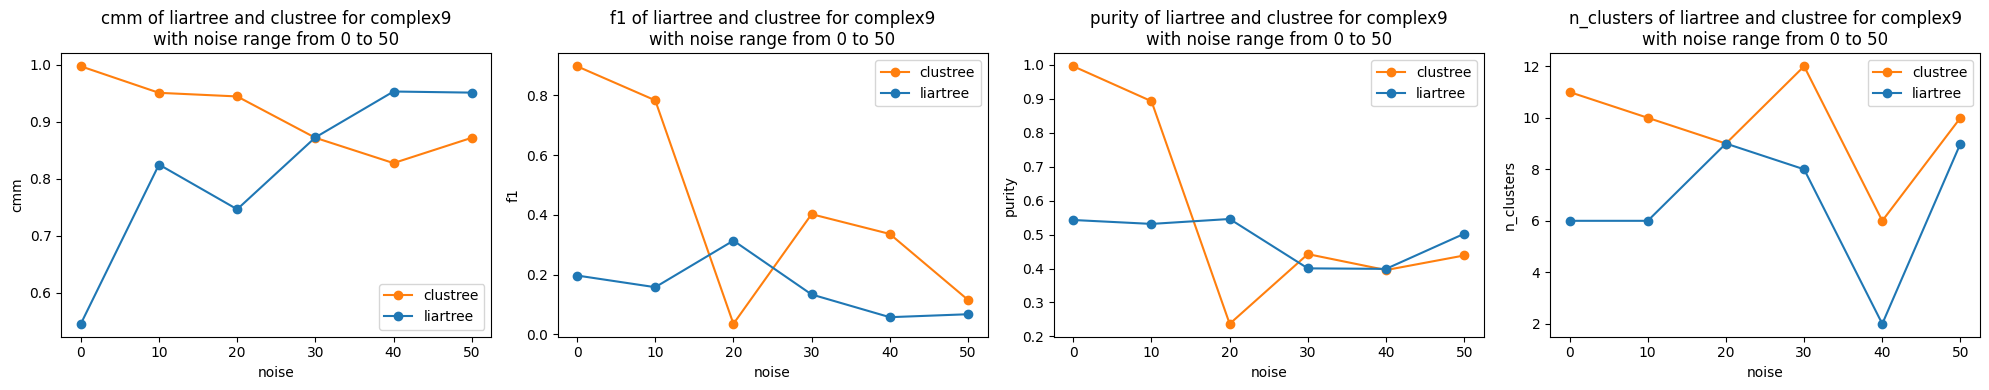

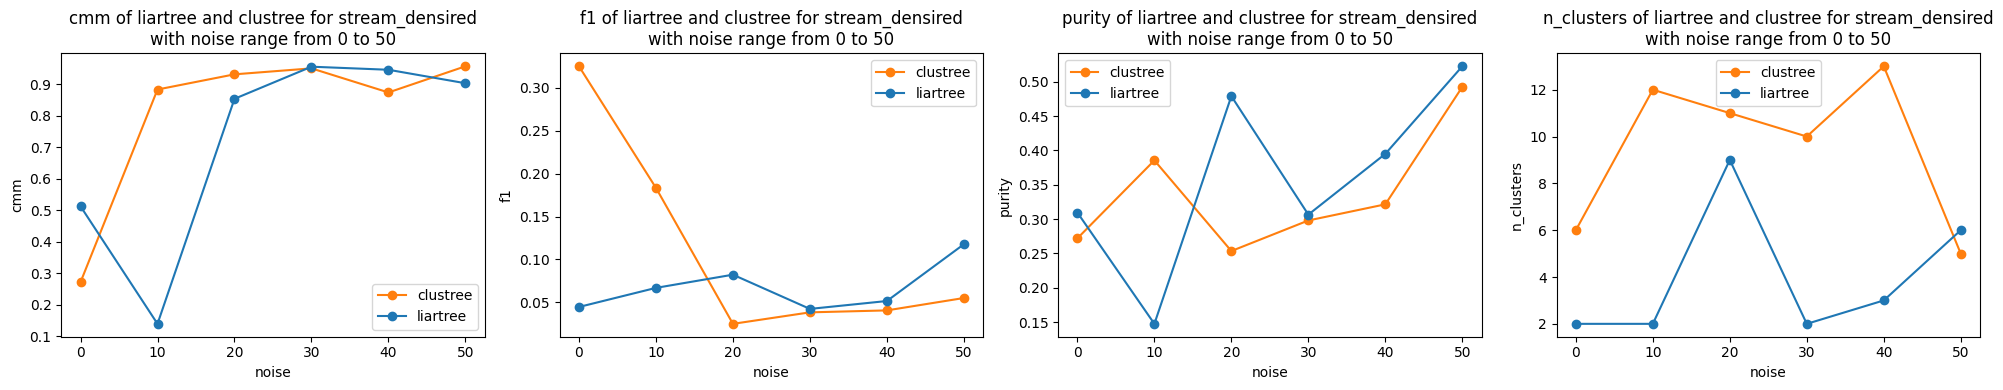

In [3]:
METRICS = ["cmm", "f1", "purity", "n_clusters"]
ALGO_COLORS = {"liartree": "tab:blue", "clustree": "tab:orange"}

base_datasets = sorted(df["base_dataset"].unique())

for dataset in base_datasets:
    sub = df[df["base_dataset"] == dataset]
    noise_min, noise_max = sub["noise"].min(), sub["noise"].max()

    fig, axes = plt.subplots(1, len(METRICS), figsize=(5 * len(METRICS), 4))
    for ax, metric in zip(axes, METRICS):
        for algo, group in sub.groupby("algorithm"):
            group = group.sort_values("noise")
            ax.plot(
                group["noise"],
                group[metric],
                marker="o",
                label=algo,
                color=ALGO_COLORS.get(algo),
            )
        ax.set_xlabel("noise")
        ax.set_ylabel(metric)
        ax.set_title(f"{metric} of liartree and clustree for {dataset}\nwith noise range from {noise_min} to {noise_max}")
        ax.legend()

    fig.tight_layout()
    plt.show()

## Live Stream Visualization

Runs each algorithm over a specified dataset batch-by-batch, live-plotting the leaf micro-clusters and their DBSCAN macro-labels, then plots CMM / purity / cluster-count over time. Structural constructor kwargs mirror `param_sweep.py`'s `BASE_TREE_KWARGS` (the fixed, untuned params); the tuned `lam` / `noise_threshold` / `eps` / `min_samples` are pulled from that algorithm+dataset's best trial in `param_sweep_results/summary.csv` (the `df` loaded above).

In [4]:
import sys
sys.path.insert(0, '.')
sys.path.insert(0, 'baseframework')
sys.path.insert(0, 'baseframework/data')
sys.path.insert(0, 'baseframework/metrics')

import time
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from IPython.display import clear_output

from baseframework import datahandler
from src.liartree import LiarTree
from src.clustree import ClusTree
from src.offline import OfflineClusterer
from cmm import get_cmm

# Structural (untuned) constructor kwargs -- same fixed values param_sweep.py
# uses for every trial (see its BASE_TREE_KWARGS). Only lam / noise_threshold /
# eps / min_samples are tuned per (algorithm, dataset), read below from summary.csv.
BASE_TREE_KWARGS = {
    "liartree": dict(max_fanout=3, leaf_capacity_max=3, descent="depthfirst",
                     budget=10**9, max_height=0, horizon=1000,
                     overlap_reduction=True),
    "clustree": dict(max_fanout=3, leaf_capacity_max=3, descent="depthfirst",
                     budget=10**9, max_height=0, horizon=1000),
}
TREE_CLASSES = {"liartree": LiarTree, "clustree": ClusTree}

_DISTINCT_COLORS = plt.cm.tab20(np.linspace(0, 1, 20))


def get_distinct_color(cluster_id):
    return _DISTINCT_COLORS[cluster_id % len(_DISTINCT_COLORS)]


def compute_purity(y_true, y_pred):
    """Weighted-majority-label purity of a clustering against ground truth."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    if len(y_true) == 0:
        return 0.0
    correct = 0
    for label in set(y_pred.tolist()):
        if label == -1:
            continue
        mask = y_pred == label
        if mask.any():
            correct += Counter(y_true[mask].tolist()).most_common(1)[0][1]
    return correct / len(y_true)


def assign_batch_labels(batch, summaries, labels_by_id):
    if len(summaries) == 0:
        return np.full(len(batch), -1)
    mc_ids = list(summaries.keys())
    centers = np.array([summaries[mid]["position"] for mid in mc_ids])
    diffs = batch[:, np.newaxis, :] - centers[np.newaxis, :, :]
    dists = np.sqrt(np.sum(diffs ** 2, axis=2))
    nearest_idx = np.argmin(dists, axis=1)
    return np.array([labels_by_id.get(mc_ids[idx], -1) for idx in nearest_idx])


def best_params(algorithm, dataset):
    """Best-trial params for (algorithm, dataset), as tuned by param_sweep.py
    and recorded in param_sweep_results/summary.csv (the `df` loaded above)."""
    rows = df[(df["algorithm"] == algorithm) & (df["dataset"] == dataset)]
    if rows.empty:
        raise ValueError(f"No summary.csv row for algorithm={algorithm!r}, dataset={dataset!r}")
    return rows.iloc[0]


def run_stream_visualization(algorithm, dataset, batch_size=300, sleep_sec=0.0, cmm_k=5, seed=0):
    """Stream `dataset` through `algorithm` batch by batch, live-plotting the
    micro-clusters, and return per-batch metric histories."""
    params = best_params(algorithm, dataset)

    tree_kwargs = dict(BASE_TREE_KWARGS[algorithm])
    tree_kwargs["lam"] = float(params["param_lam"])
    if algorithm == "liartree":
        tree_kwargs["noise_threshold"] = float(params["param_noise_threshold"])
    tree = TREE_CLASSES[algorithm](**tree_kwargs)

    offline = OfflineClusterer(
        method="dbscan", eps=float(params["param_eps"]),
        min_samples=int(params["param_min_samples"]),
        weighted=False, random_state=seed,
    )

    X, y_true = datahandler.load_data(dataset)
    num_batches = len(X) // batch_size + 1

    history = {"batch": [], "cmm": [], "purity": [], "n_clusters": []}

    for i in range(num_batches):
        start_idx = i * batch_size
        end_idx = min((i + 1) * batch_size, len(X))
        batch = X[start_idx:end_idx]
        y_batch = y_true[start_idx:end_idx]
        if len(batch) == 0:
            break

        timestamps = np.arange(start_idx, end_idx) + 1
        tree.learn(batch, timestamps)

        summaries = tree.get_summary()
        labels_by_id = offline.predict_summaries(summaries)
        batch_labels = assign_batch_labels(batch, summaries, labels_by_id)

        unique_clusters = set(v for v in labels_by_id.values() if v != -1)
        num_clusters = len(unique_clusters)
        purity = compute_purity(y_batch, batch_labels)

        valid_mask = batch_labels != -1
        if len(set(batch_labels[valid_mask])) >= 2 and valid_mask.sum() >= 10:
            try:
                cmm_val = get_cmm(batch, y_batch, batch_labels, np.ones(len(batch)), cmm_k)
            except Exception:
                cmm_val = float("nan")
        else:
            cmm_val = float("nan")

        history["batch"].append(i + 1)
        history["cmm"].append(cmm_val)
        history["purity"].append(purity)
        history["n_clusters"].append(num_clusters)

        clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(10, 8))
        ax.scatter(X[:, 0], X[:, 1], c="whitesmoke", s=10, zorder=0)
        ax.scatter(batch[:, 0], batch[:, 1], c="red", s=15, alpha=0.8, label="New Arrivals", zorder=2)

        for mc_id, mc in summaries.items():
            center, radius = mc["position"], mc["radius"]
            cluster_id = labels_by_id.get(mc_id, -1)
            if cluster_id == -1:
                color, alpha, edge_style = "black", 0.1, "--"
            else:
                color, alpha, edge_style = get_distinct_color(cluster_id), 0.5, "-"
            circle = Circle(center, max(radius, 0.005), linewidth=1, edgecolor="black",
                            linestyle=edge_style, facecolor=color, alpha=alpha, zorder=1)
            ax.add_patch(circle)

        cmm_str = f"{cmm_val:.3f}" if not np.isnan(cmm_val) else "N/A"
        ax.set_title(
            f"{algorithm} Live [{dataset}] - Batch {i+1} | Clusters: {num_clusters} | "
            f"Purity: {purity:.3f} | CMM: {cmm_str} | Microclusters: {len(summaries)}, "
            f"Avg Radius: {tree.avg_leaf_radius():.4f}"
        )
        ax.set_aspect("equal", "box")
        ax.legend(loc="upper right")
        plt.show()
        if sleep_sec:
            time.sleep(sleep_sec)

    return history


def plot_metric_history(history, algorithm, dataset):
    fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

    axes[0].plot(history["batch"], history["cmm"], color="steelblue", marker="o", markersize=3, linewidth=1.5)
    axes[0].set_ylabel("CMM")
    axes[0].set_title(f"{algorithm} clustering quality metrics over time [{dataset}]")
    axes[0].set_ylim(0, 1)
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(history["batch"], history["purity"], color="seagreen", marker="o", markersize=3, linewidth=1.5)
    axes[1].set_ylabel("Purity")
    axes[1].set_ylim(0, 1)
    axes[1].grid(True, alpha=0.3)

    axes[2].plot(history["batch"], history["n_clusters"], color="darkorange", marker="o", markersize=3, linewidth=1.5)
    axes[2].set_ylabel("Cluster Count")
    axes[2].set_xlabel("Batch Step")
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


### LiarTree

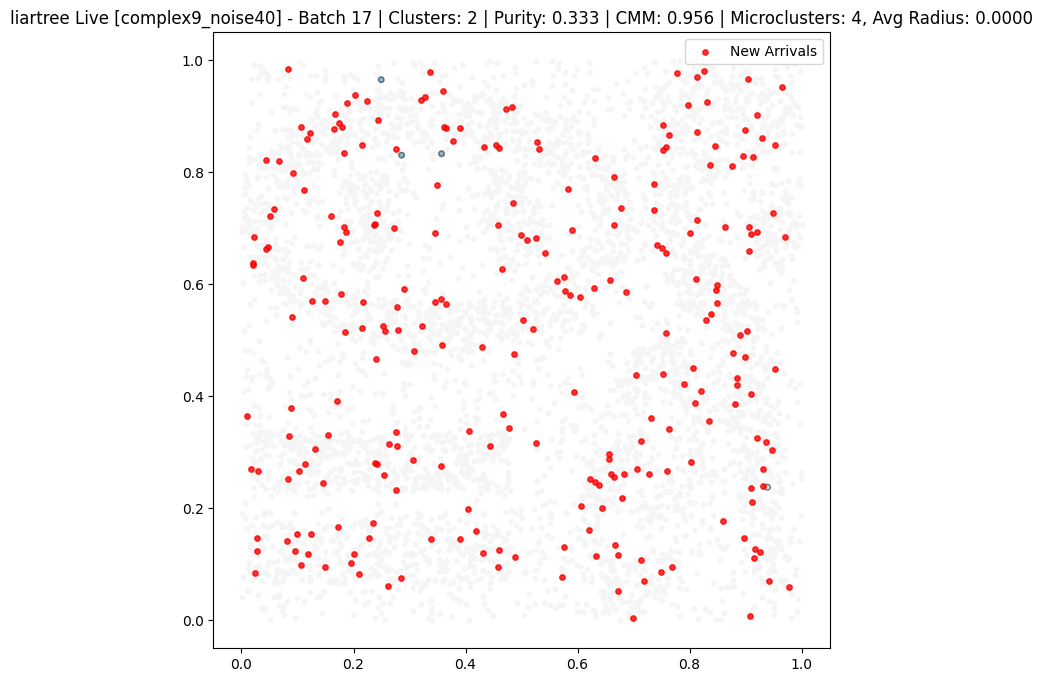

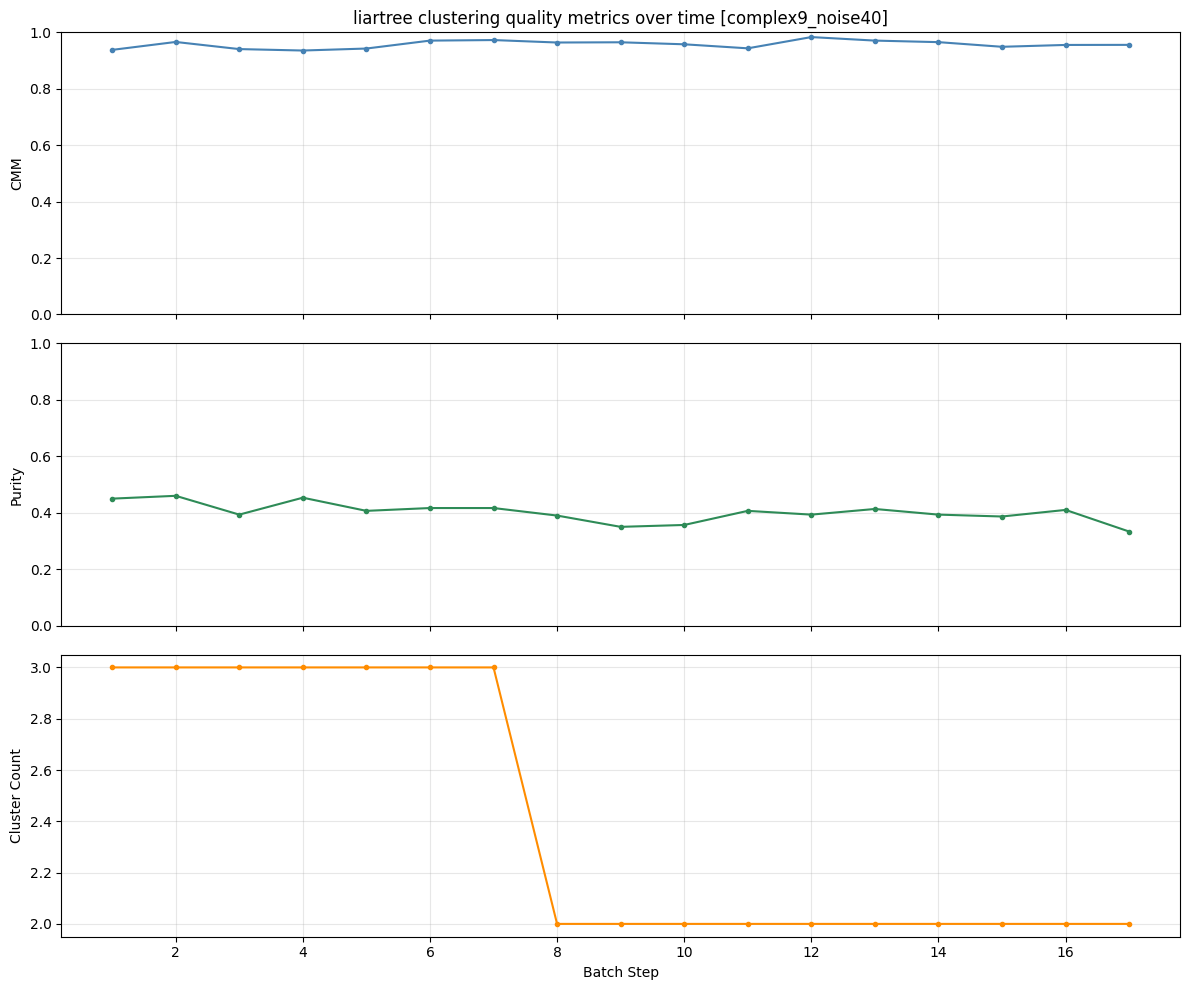

In [5]:
# ── Config ───────────────────────────────────────────────────────────────
DATASET_LT = "complex9_noise40"  # choose a dataset to run LiarTree on -- must have a
                          # matching row in param_sweep_results/summary.csv
# ────────────────────────────────────────────────────────────────────────

lt_history = run_stream_visualization("liartree", DATASET_LT)
plot_metric_history(lt_history, "liartree", DATASET_LT)


### ClusTree

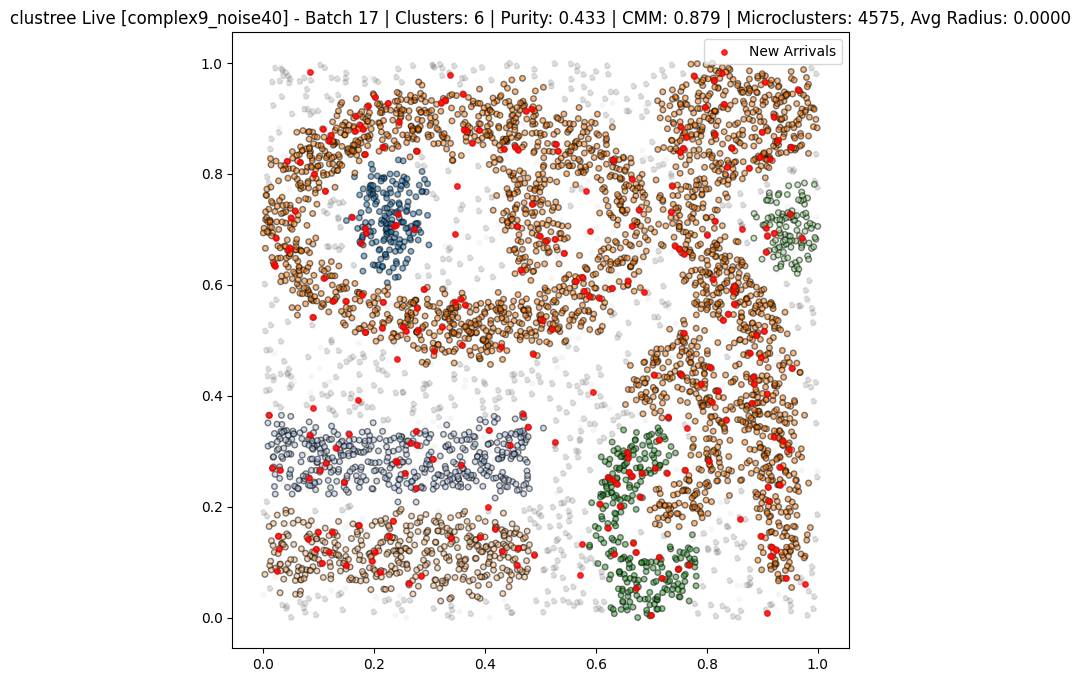

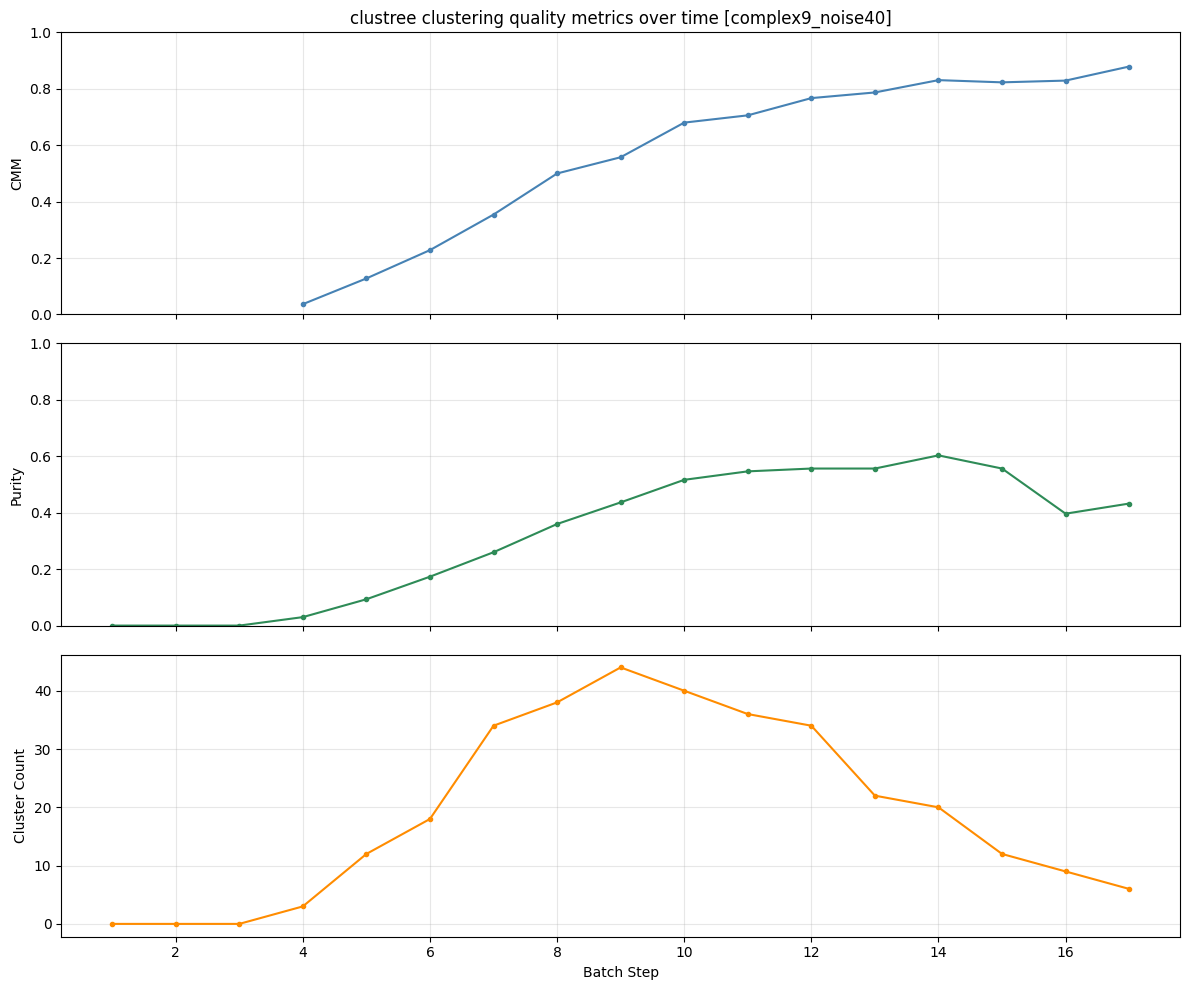

In [6]:
# ── Config ───────────────────────────────────────────────────────────────
DATASET_CT = "complex9_noise40"  # choose a dataset to run ClusTree on -- must have a
                          # matching row in param_sweep_results/summary.csv
# ────────────────────────────────────────────────────────────────────────

ct_history = run_stream_visualization("clustree", DATASET_CT)
plot_metric_history(ct_history, "clustree", DATASET_CT)
